---

# Decision Tree Learning: Pembatalan Pesanan Ronaldo Hotel

*Pohon keputusan C4.5 from scratch beserta perbandingannya dengan scikit-learn.*

---

## Kelompok G04: TreeIsAllYouNeed

---

## Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Data Understanding**](#3)
4. [**Persiapan Data**](#4)
5. [**Feature Selection dan Dimensionality Reduction**](#5)
6. [**Modeling dan Validasi**](#6)
7. [**Perbandingan dengan scikit-learn**](#7)
8. [**Bonus: Cost-Sensitive Classification**](#8)
9. [**Model Akhir dan Submission Kaggle**](#9)
10. [**Bonus: Gambar Pohon**](#10)
11. [**Kesimpulan**](#11)
12. [**Referensi**](#12)

---

# Pendahuluan <a name="1"></a>

---

Notebook ini melatih class `DTL` di `src/algoritma/dtl/`, yaitu pohon C4.5 dengan gain ratio. Class ini menangani
fitur numerik (threshold biner), fitur kategorikal (cabang per nilai), dan nilai kosong (bobot fraksional). Metrik
utamanya Macro F1, sesuai kompetisi.

| Model submission | Skor publik Kaggle | Macro F1, CV 5-fold |
|---|---|---|
| DTL C4.5 | 0,87393 | 0,8672 (10 seed) |

Semua CV di notebook ini memakai satu seed (42) dan menghitung ulang fitur di dalam tiap fold.

---

# Inisialisasi <a name="2"></a>

---

Pustaka scikit-learn hanya dipakai sebagai pembanding, untuk membagi data, dan untuk menghitung metrik.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "kaggle" / "dataset" / "train.csv").exists())
for folder in ("algoritma", "kaggle"):
    sys.path.insert(0, str(REPO / "src" / folder))

from booking_features import build_features, clean, load_data, standardize
from dtl import DTL
from dtl.splitting import best_split_continuous

In [2]:
SEED = 42
FOLDS = 5
THRESHOLD = 0.4
FINAL = dict(max_depth=20, min_samples_leaf=2, pruning="cost_complexity", ccp_alpha=2.5)
NEG_COLOR, POS_COLOR, MUTED = "#2a78d6", "#eb6834", "#52514e"

DATA = REPO / "src" / "kaggle" / "dataset"
OUTPUT = REPO / "output" / "dtl"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


train_raw, test = load_data(DATA)
print("train:", train_raw.shape, " test:", test.shape)

train: (27373, 19)  test: (6844, 18)


---

# Data Understanding <a name="3"></a>

---

Bagian ini melihat keseimbangan target dan nilai kosong, dua hal yang paling memengaruhi pemrosesan untuk pohon.
Eksplorasi lengkap ada di `eda.ipynb`.

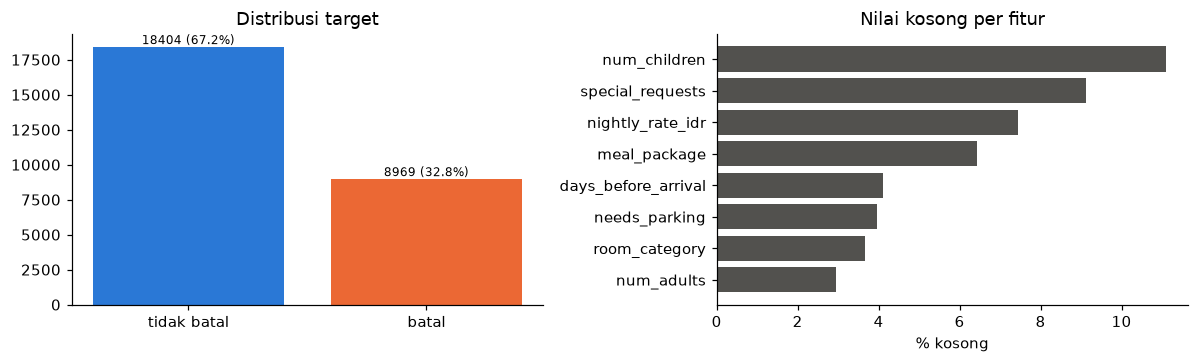

duplikat persis (tanpa id): 64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
counts = train_raw["is_canceled"].value_counts().sort_index()
axes[0].bar(["tidak batal", "batal"], counts, color=[NEG_COLOR, POS_COLOR])
for i, v in enumerate(counts):
    axes[0].text(i, v, f"{v} ({v / len(train_raw):.1%})", ha="center", va="bottom", fontsize=8)
axes[0].set_title("Distribusi target")
missing = train_raw.isna().mean().loc[lambda s: s > 0].sort_values()
axes[1].barh(missing.index, missing * 100, color=MUTED)
axes[1].set_xlabel("% kosong")
axes[1].set_title("Nilai kosong per fitur")
fig.tight_layout()
plt.show()
print("duplikat persis (tanpa id):", int(train_raw.drop(columns="id").duplicated().sum()))

#### Insights

> Target tidak seimbang, sekitar 67 banding 33, sehingga Macro F1 dan ambang keputusan diperhatikan. Delapan fitur
> memiliki nilai kosong, dan ada duplikat persis yang perlu dibuang.

---

# Persiapan Data <a name="4"></a>

---

Duplikat persis pada train dibuang. Nilai kosong diisi median atau modus disertai penanda kosong, dan kategori
di-one-hot. Pohon tidak butuh standardisasi. Fitur tambahan terdiri atas tanggal booking, lama menginap, dan fitur
saudara, yaitu rata-rata label booking lain yang kemungkinan satu rombongan. Saudara harus memiliki tanggal datang,
jumlah malam, dan kanal yang sama persis, selisih lead time paling banyak 10 hari, selisih harga paling banyak 5%,
serta kolom lunak yang sama atau kosong.

Train dan test diproses terpisah, dan semua statistik berasal dari data latih. Fitur saudara untuk baris latih
dihitung out-of-fold sehingga label baris itu sendiri tidak terlihat. Pada CV, fitur dihitung ulang di tiap fold.

In [4]:
train = clean(train_raw)
y = train["is_canceled"].to_numpy()
print("train:", len(train_raw), "->", len(train), "baris")

folds = list(StratifiedKFold(FOLDS, shuffle=True, random_state=SEED).split(train, y))
fold_features = [build_features(train.iloc[a], y[a], train.iloc[b], shared_neighbours=False) for a, b in folds]
print("fitur:", fold_features[0][0].shape[1])


def oof(make_model, transform=lambda A, B: (A, B)):
    proba, leaves, started = np.zeros(len(y)), [], time.time()
    for (a, b), (A, B) in zip(folds, fold_features):
        A, B = transform(A, B)
        model = make_model().fit(A, y[a])
        proba[b] = model.predict_proba(B)[:, 1]
        leaves.append(model.n_leaves_ if isinstance(model, DTL) else model.get_n_leaves())
    return proba, np.mean(leaves), time.time() - started


def summary(name, proba, leaves, seconds, threshold=THRESHOLD):
    p = (proba >= threshold).astype(int)
    scores = [macro_f1(y[b], p[b]) for _, b in folds]
    return {"model": name, "macro_f1": np.mean(scores), "std": np.std(scores), "akurasi": accuracy_score(y, p),
            "presisi_batal": precision_score(y, p), "recall_batal": recall_score(y, p), "daun": leaves,
            "detik": seconds}

train: 27373 -> 27309 baris


fitur: 46


---

# Feature Selection dan Dimensionality Reduction <a name="5"></a>

---

Tiap fitur diberi peringkat berdasarkan information gain terbaiknya pada data latih tiap fold, lalu diuji
apakah membuang fitur berperingkat rendah menaikkan skor. Reduksi dimensi diuji dengan PCA yang mempertahankan 95%
variansi.

In [5]:
def gains(A, labels):
    w = np.ones(len(labels))
    best = {c: max((g for g, _, _ in best_split_continuous(A[c].to_numpy(float), labels, w, 2, 2)), default=0.0)
            for c in A.columns}
    return pd.Series(best).sort_values(ascending=False)


fold_gains = [gains(A, y[a]) for (a, _), (A, _) in zip(folds, fold_features)]


def top_k(k):
    ranking = iter(fold_gains)

    def transform(A, B):
        keep = next(ranking).index[:k]
        return A[keep], B[keep]
    return transform


def pca(A, B, keep=0.95):
    A, B, _ = standardize(A, B)
    _, s, components = np.linalg.svd(A, full_matrices=False)
    k = int(np.searchsorted(np.cumsum(s ** 2) / np.sum(s ** 2), keep)) + 1
    return A @ components[:k].T, B @ components[:k].T


full = oof(lambda: DTL(**FINAL))
rows = [summary("semua fitur", *full)]
for k in (30, 20, 12):
    rows.append(summary(f"top-{k} fitur", *oof(lambda: DTL(**FINAL), top_k(k))))
rows.append(summary("PCA 95%", *oof(lambda: DTL(**FINAL), pca)))
selection = pd.DataFrame(rows)
selection.to_csv(OUTPUT / "dtl_feature_selection.csv", index=False)
display(pd.concat(fold_gains, axis=1).mean(axis=1).sort_values(ascending=False).head(10).rename("gain").to_frame().T.round(4))
selection.round(4)

,sib_te,days_before_arrival,special_requests,arr_ord,arrival_year,sib_n,book_ord,nightly_rate_idr,arrival_month,is_returning_guest
gain,0.1994,0.1127,0.0431,0.0408,0.026,0.0184,0.0174,0.0156,0.0146,0.0123


,model,macro_f1,std,akurasi,presisi_batal,recall_batal,daun,detik
0,semua fitur,0.8692,0.0030,0.8870,0.8538,0.7904,65.6,22.2235
1,top-30 fitur,0.8697,0.0036,0.8874,0.8540,0.7915,64.2,15.3343
2,top-20 fitur,0.8677,0.0034,0.8859,0.8541,0.7860,72.2,12.1449
3,top-12 fitur,0.8426,0.0029,0.8641,0.8168,0.7545,103.0,15.4321
4,PCA 95%,0.7804,0.0034,0.8088,0.7176,0.6863,304.8,89.0998


#### Insights

> Membuang fitur tidak memberi kenaikan yang berarti. Top-30 hanya naik 0,0005, jauh di bawah simpangan baku antar-fold
> (0,003), sedangkan top-12 turun 0,027. Semua fitur dipertahankan, karena pohon sudah memilih fitur sendiri.

> PCA menurunkan skor menjadi 0,7804 dan membuat pohon jauh lebih besar. Komponen PCA mencampur fitur, sehingga
> split sejajar sumbu kehilangan maknanya. PCA tidak dipakai.

---

# Modeling dan Validasi <a name="6"></a>

---

Beberapa strategi pruning dibandingkan. Reduced-error pruning ada di materi kuliah, sedangkan pessimistic dan
cost-complexity pruning di luar materi. Pada class `DTL`, `ccp_alpha` dihitung dalam jumlah baris, sehingga
`ccp_alpha` = 2,5 berarti subtree dipangkas jika hanya mengurangi kurang dari 2,5 kesalahan per daun tambahan.

Varian "data mentah" memberikan kolom asli tanpa imputasi dan tanpa one-hot, sehingga class `DTL` sendiri yang
menangani kategori dan nilai kosong. Varian ini dibatasi ke kedalaman 10 dan daun minimum 10, karena baris dengan
nilai kosong diteruskan ke semua cabang sehingga pohon dalam menjadi sangat lambat.

In [6]:
def raw(A, B):
    (a, b) = next(raw_folds)
    drop = lambda df: df.drop(columns=["is_canceled"]).reset_index(drop=True)
    return drop(train.iloc[a]), drop(train.iloc[b])


base = dict(max_depth=20, min_samples_leaf=2)
configs = {
    "tanpa pruning": dict(base),
    "reduced-error (val 30%)": dict(base, pruning="reduced_error"),
    "pessimistic CF=0,03": dict(base, pruning="pessimistic", confidence=0.03),
    "cost-complexity 1,0": dict(base, pruning="cost_complexity", ccp_alpha=1.0),
    "cost-complexity 2,5 (dipakai)": FINAL,
    "cost-complexity 5,0": dict(base, pruning="cost_complexity", ccp_alpha=5.0),
    "cost-complexity 2,5, information gain": dict(FINAL, split_criterion="gain"),
}
rows = [summary(name, *(full if params is FINAL else oof(lambda: DTL(**params)))) for name, params in configs.items()]
raw_folds = iter(folds)
raw_params = dict(FINAL, max_depth=10, min_samples_leaf=10, missing_predict="distribute")
rows.append(summary("data mentah, kedalaman 10, daun 10", *oof(lambda: DTL(**raw_params), raw)))
pruning = pd.DataFrame(rows)
pruning.to_csv(OUTPUT / "dtl_pruning.csv", index=False)
pruning.round(4)

,model,macro_f1,std,akurasi,presisi_batal,recall_batal,daun,detik
0,tanpa pruning,0.8497,0.0048,0.8675,0.7970,0.7990,688.4,28.2126
1,reduced-error (val 30%),0.8625,0.0025,0.8801,0.8302,0.7970,115.2,15.6180
2,"pessimistic CF=0,03",0.8685,0.0024,0.8863,0.8512,0.7911,81.8,18.9379
3,"cost-complexity 1,0",0.8623,0.0026,0.8801,0.8321,0.7942,254.8,49.4044
4,"cost-complexity 2,5 (dipakai)",0.8692,0.0030,0.8870,0.8538,0.7904,65.6,22.2235
5,"cost-complexity 5,0",0.8671,0.0042,0.8849,0.8469,0.7917,33.2,39.6568
6,"cost-complexity 2,5, information gain",0.8627,0.0033,0.8815,0.8463,0.7800,132.2,68.7959
7,"data mentah, kedalaman 10, daun 10",0.8134,0.0070,0.8390,0.7746,0.7168,71.4,9.8052


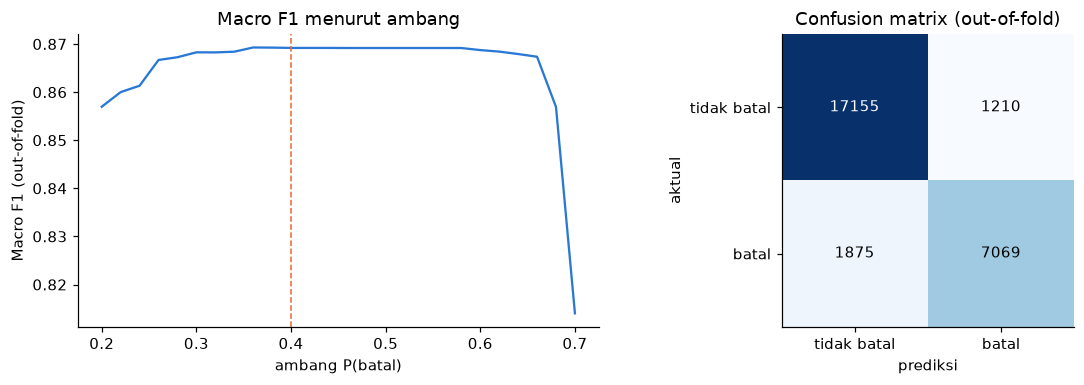

In [7]:
thresholds = np.round(np.arange(0.2, 0.71, 0.02), 2)
curve = [macro_f1(y, (full[0] >= t).astype(int)) for t in thresholds]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(thresholds, curve, color=NEG_COLOR)
axes[0].axvline(THRESHOLD, color=POS_COLOR, ls="--", lw=1)
axes[0].set_xlabel("ambang P(batal)")
axes[0].set_ylabel("Macro F1 (out-of-fold)")
axes[0].set_title("Macro F1 menurut ambang")
matrix = confusion_matrix(y, (full[0] >= THRESHOLD).astype(int))
axes[1].imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, matrix[i, j], ha="center", va="center",
                     color="white" if matrix[i, j] > matrix.max() / 2 else "black")
axes[1].set_xticks([0, 1], ["tidak batal", "batal"])
axes[1].set_yticks([0, 1], ["tidak batal", "batal"])
axes[1].set_xlabel("prediksi")
axes[1].set_ylabel("aktual")
axes[1].set_title("Confusion matrix (out-of-fold)")
fig.tight_layout()
fig.savefig(OUTPUT / "dtl_validation.png", bbox_inches="tight")
plt.show()

#### Insights

> Tanpa pruning pohon memiliki sekitar 688 daun dan skor 0,8497, tanda overfit. Cost-complexity 2,5 memangkasnya
> menjadi 66 daun dan menaikkan skor ke 0,8692. Pessimistic pruning hampir sama (0,8685), sedangkan reduced-error lebih
> rendah (0,8625) karena 30% data latih dipakai untuk validasi.

> Gain ratio lebih baik daripada information gain (0,8692 banding 0,8627), sesuai alasan C4.5 di materi kuliah.

> Class `DTL` bisa dilatih langsung pada kategori dan nilai kosong. Skornya 0,8134, lebih rendah karena varian ini tidak
> memakai fitur saudara dan fitur tanggal booking.

> Kurva Macro F1 landai di sekitar ambang 0,4, sehingga hasilnya tidak peka terhadap pilihan ambang.

---

# Perbandingan dengan scikit-learn <a name="7"></a>

---

`DecisionTreeClassifier` dijalankan dengan pemetaan parameter dari spesifikasi pada fitur, fold, kedalaman, dan
ukuran daun minimum yang sama. Nilai `ccp_alpha` di scikit-learn memakai satuan impurity, sehingga dipilih sendiri
lewat CV. Ambang 0,5 dan 0,4 ditampilkan untuk semua model.

In [8]:
def sk(**params):
    return lambda: DecisionTreeClassifier(max_depth=20, min_samples_leaf=2, random_state=SEED, **params)


results = {"DTL from scratch (C4.5)": full,
           "DTL from scratch tanpa pruning": oof(lambda: DTL(**base)),
           "sklearn entropy (ID3)": oof(sk(criterion="entropy")),
           "sklearn gini (CART)": oof(sk(criterion="gini"))}
for label, criterion in (("entropy + ccp_alpha (C4.5)", "entropy"), ("gini + ccp_alpha", "gini")):
    tried = {a: oof(sk(criterion=criterion, ccp_alpha=a)) for a in (5e-5, 1e-4, 2e-4, 4e-4, 8e-4)}
    best = max(tried, key=lambda a: macro_f1(y, (tried[a][0] >= THRESHOLD).astype(int)))
    results[f"sklearn {label}, alpha={best:g}"] = tried[best]
rows = []
for name, result in results.items():
    row = summary(name, *result)
    row["macro_f1_ambang_0,5"] = summary(name, *result, threshold=0.5)["macro_f1"]
    rows.append(row)
comparison = pd.DataFrame(rows)
comparison.to_csv(OUTPUT / "dtl_comparison.csv", index=False)
comparison.round(4)

,model,macro_f1,std,akurasi,presisi_batal,recall_batal,daun,detik,"macro_f1_ambang_0,5"
0,DTL from scratch (C4.5),0.8692,0.0030,0.8870,0.8538,0.7904,65.6,22.2235,0.8692
1,DTL from scratch tanpa pruning,0.8497,0.0048,0.8675,0.7970,0.7990,688.4,16.1325,0.8517
2,sklearn entropy (ID3),0.8288,0.0043,0.8471,0.7531,0.7933,1285.4,1.0457,0.8292
3,sklearn gini (CART),0.8246,0.0037,0.8428,0.7428,0.7952,1463.2,0.9238,0.8250
4,"sklearn entropy + ccp_alpha (C4.5), alpha=0.0008",0.8638,0.0034,0.8812,0.8309,0.8001,64.2,1.4780,0.8642
5,"sklearn gini + ccp_alpha, alpha=0.0004",0.8642,0.0050,0.8819,0.8365,0.7948,45.6,1.8732,0.8642


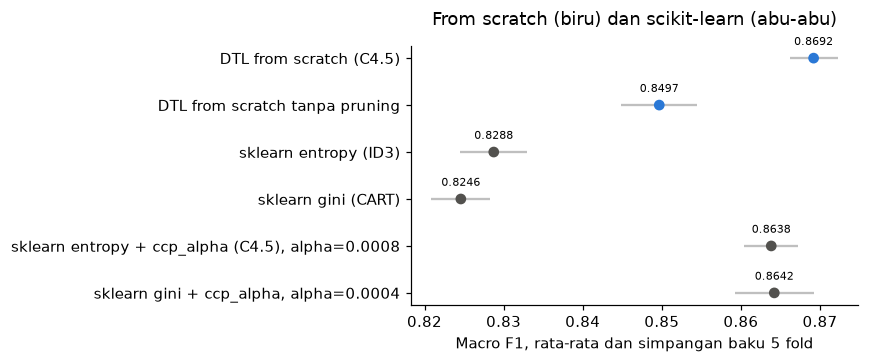

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.4))
pos = np.arange(len(comparison))
colors = [NEG_COLOR if n.startswith("DTL") else MUTED for n in comparison["model"]]
ax.errorbar(comparison["macro_f1"], pos, xerr=comparison["std"], fmt="none", ecolor="0.75", zorder=1)
ax.scatter(comparison["macro_f1"], pos, color=colors, s=36, zorder=2)
for x, i in zip(comparison["macro_f1"], pos):
    ax.text(x, i - 0.28, f"{x:.4f}", fontsize=7, ha="center")
ax.set_yticks(pos, comparison["model"])
ax.invert_yaxis()
ax.set_xlabel("Macro F1, rata-rata dan simpangan baku 5 fold")
ax.set_title("From scratch (biru) dan scikit-learn (abu-abu)", pad=14)
fig.tight_layout()
fig.savefig(OUTPUT / "dtl_comparison.png", bbox_inches="tight")
plt.show()

#### Insights

> Dengan pruning, DTL from scratch mencapai 0,8692, sedikit di atas scikit-learn (0,8638 untuk entropy + `ccp_alpha` dan
> 0,8642 untuk gini + `ccp_alpha`). Tanpa pruning, selisihnya lebih besar (0,8497 banding 0,8288 dan 0,8246).

> Perbedaan ini wajar karena algoritmanya tidak sama. scikit-learn tidak punya gain ratio, sehingga pemetaan C4.5 dari
> spesifikasi memakai entropy biasa, dan pruning-nya menghitung impurity, bukan jumlah kesalahan. scikit-learn jauh
> lebih cepat karena ditulis dengan Cython.

---

# Bonus: Cost-Sensitive Classification <a name="8"></a>

---

False Positive dianggap dua kali lebih mahal daripada False Negative, sehingga biaya = 2 x FP + FN. Jika
probabilitas daun benar, keputusan berbiaya minimum adalah memprediksi batal hanya jika P(batal) > 2/3. Cara kedua
memberi bobot 2 pada kelas tidak batal saat pelatihan, lalu memakai ambang 0,5. Semua angka berasal dari prediksi
out-of-fold.

,penanganan,FP,FN,biaya,biaya_per_booking,macro_f1
0,"biasa (ambang 0,4)",1210,1875,4295,0.1573,0.8692
1,"biasa (ambang 0,5)",1202,1882,4286,0.1569,0.8692
2,ambang 2/3,1141,1971,4253,0.1557,0.8674
3,"bobot kelas 2:1 (ambang 0,5)",817,2490,4124,0.1510,0.8550


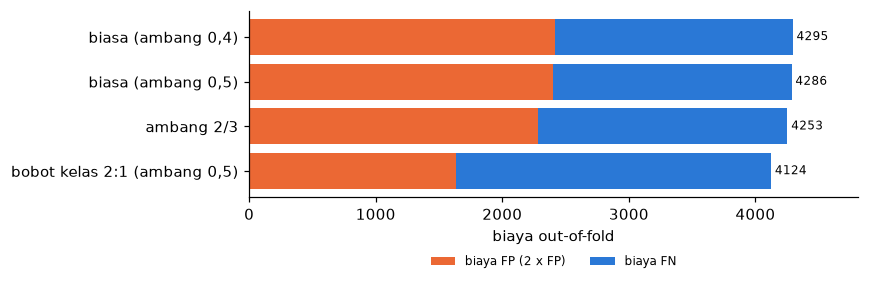

In [10]:
COST_FP, COST_FN = 2, 1
weighted = oof(lambda: DTL(**FINAL, class_weight={0: float(COST_FP), 1: float(COST_FN)}))
rows = []
for name, proba, t in (("biasa (ambang 0,4)", full[0], THRESHOLD), ("biasa (ambang 0,5)", full[0], 0.5),
                       ("ambang 2/3", full[0], 2 / 3), ("bobot kelas 2:1 (ambang 0,5)", weighted[0], 0.5)):
    p = (proba >= t).astype(int)
    fp, fn = int(((p == 1) & (y == 0)).sum()), int(((p == 0) & (y == 1)).sum())
    rows.append({"penanganan": name, "FP": fp, "FN": fn, "biaya": COST_FP * fp + COST_FN * fn,
                 "biaya_per_booking": (COST_FP * fp + COST_FN * fn) / len(y), "macro_f1": macro_f1(y, p)})
cost_table = pd.DataFrame(rows)
cost_table.to_csv(OUTPUT / "dtl_cost_sensitive.csv", index=False)
display(cost_table.round(4))

fig, ax = plt.subplots(figsize=(8, 2.8))
pos = np.arange(len(cost_table))
ax.barh(pos, COST_FP * cost_table["FP"], color=POS_COLOR, label="biaya FP (2 x FP)")
ax.barh(pos, cost_table["FN"], left=COST_FP * cost_table["FP"], color=NEG_COLOR, label="biaya FN")
for i, cost in enumerate(cost_table["biaya"]):
    ax.text(cost + 30, i, str(cost), va="center", fontsize=8)
ax.set_yticks(pos, cost_table["penanganan"])
ax.invert_yaxis()
ax.set_xlim(0, cost_table["biaya"].max() * 1.12)
ax.set_xlabel("biaya out-of-fold")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "dtl_cost_sensitive.png", bbox_inches="tight")
plt.show()

#### Insights

> Menggeser ambang ke 2/3 hampir tidak menurunkan biaya (4.286 menjadi 4.253 dibanding ambang 0,5), karena sebagian besar
> daun sudah sangat murni dan sedikit yang probabilitasnya di antara 0,5 dan 2/3.

> Bobot kelas 2:1 lebih efektif, karena mengubah split dan pruning saat pelatihan. FP turun dari 1.202 menjadi 817 dan
> biaya menjadi 4.124, dengan imbalan Macro F1 turun dari 0,8692 ke 0,8550. Submission Kaggle tetap memakai model biasa,
> karena dinilai dengan Macro F1.

---

# Model Akhir dan Submission Kaggle <a name="9"></a>

---

Pohon akhir dilatih pada seluruh train, disimpan, dimuat kembali, lalu dipakai untuk prediksi. Booking diprediksi
batal jika P(batal) minimal 0,4.

In [11]:
X, X_test = build_features(train, y, test, shared_neighbours=False)
tree = DTL(**FINAL).fit(X, y)
print("daun:", tree.n_leaves_, " kedalaman:", tree.depth_)

tree.save(OUTPUT / "dtl_model.json")
tree = DTL.load(OUTPUT / "dtl_model.json")

# Sumber ambang: C. Elkan, "The Foundations of Cost-Sensitive Learning", IJCAI 2001
labels = (tree.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)
submission = pd.DataFrame({"id": test["id"], "is_canceled": labels})
sample = pd.read_csv(DATA / "sample_submission.csv", dtype={"id": str})
assert list(submission.columns) == list(sample.columns)
assert submission["id"].tolist() == sample["id"].tolist()
submission.to_csv(OUTPUT / "submission.csv", index=False)
print("baris:", len(submission), " rasio batal:", round(labels.mean(), 4))

daun: 82  kedalaman: 20
baris: 6844  rasio batal: 0.3025


---

# Bonus: Gambar Pohon <a name="10"></a>

---

`DTL.plot` menggambar pohon. Parameter `top_n` mengatur banyak percabangan yang ditampilkan, dipilih dari akar ke
bawah mulai dari percabangan yang dilalui booking terbanyak. Kotak putih adalah percabangan, kotak berwarna adalah
daun, dan kotak bergaris putus-putus adalah subtree yang tidak ditampilkan. `top_n=None` menggambar seluruh pohon.

tree_top7.png: 7 percabangan


tree_top15.png: 15 percabangan


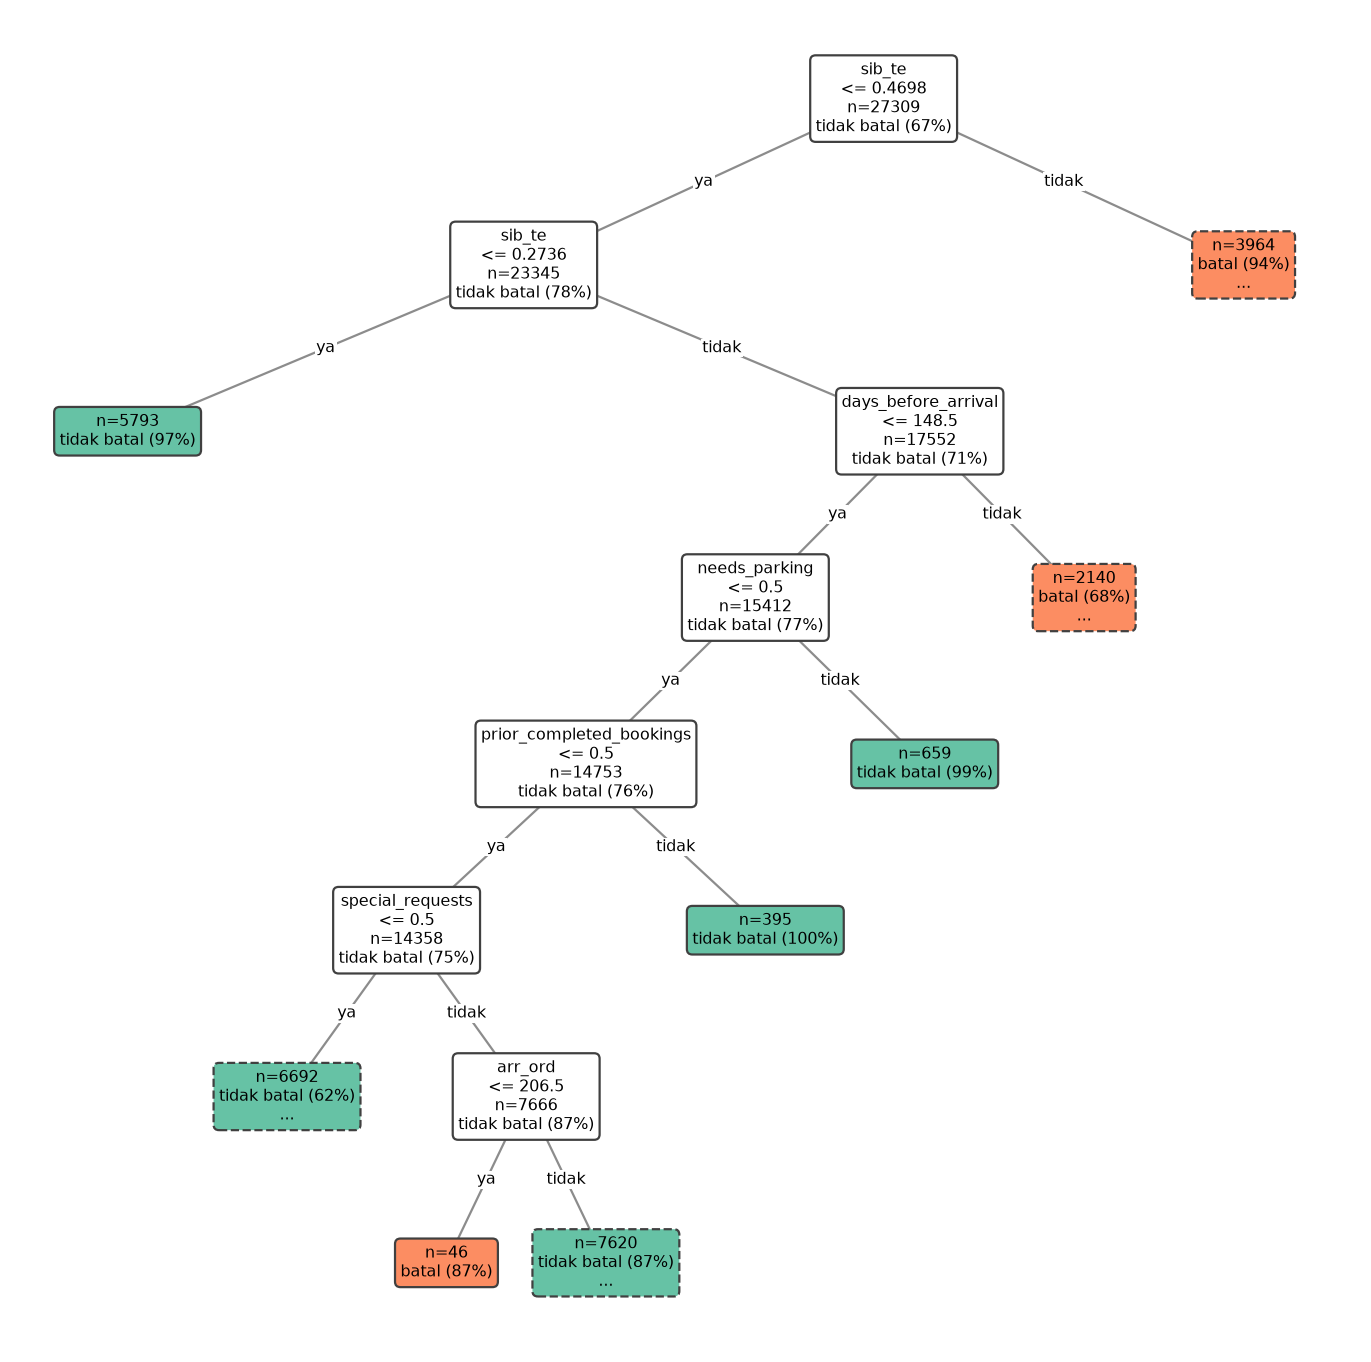

In [12]:
TOP_N = 7
for n in (TOP_N, 15):
    shown = tree.plot(OUTPUT / f"tree_top{n}.png", top_n=n, class_names=["tidak batal", "batal"])
    print(f"tree_top{n}.png: {shown} percabangan")
Image(str(OUTPUT / f"tree_top{TOP_N}.png"), width=800)

#### Insights

> Akar pohon adalah rata-rata label saudara (`sib_te`). Booking yang saudaranya umumnya batal hampir pasti batal. Untuk
> sisanya, lead time, permintaan parkir, riwayat booking, dan permintaan khusus menjadi pembeda berikutnya. Gambar dengan
> 15 percabangan ada di `output/dtl/tree_top15.png`.

---

# Kesimpulan <a name="11"></a>

---

- DTL C4.5 from scratch mencapai Macro F1 0,8692 pada CV 5-fold (seed 42) dan 0,8672 sebagai rata-rata 10 seed.
- Pruning adalah penentu utama. Cost-complexity pruning menaikkan skor dari 0,8497 ke 0,8692.
- Hasilnya sedikit di atas `DecisionTreeClassifier` pada fitur dan fold yang sama.
- Untuk biaya FP dua kali FN, bobot kelas 2:1 menurunkan biaya out-of-fold dari 4.286 menjadi 4.124.

---

# Referensi <a name="12"></a>

---

Materi kuliah: salindia Decision Tree dan Issues in Decision Tree, IF3170, 2026. Metode di luar materi kuliah:

1. L. Breiman dkk., *Classification and Regression Trees*, 1984 (cost-complexity pruning).
2. J. R. Quinlan, *C4.5: Programs for Machine Learning*, 1993 (pessimistic pruning).
3. C. Elkan, "The Foundations of Cost-Sensitive Learning", IJCAI 2001 (ambang keputusan).
4. K. M. Ting, "An instance-weighting method to induce cost-sensitive trees", IEEE TKDE 14(3), 2002.
5. D. Micci-Barreca, "A preprocessing scheme for high-cardinality categorical attributes", SIGKDD Explorations
   3(1), 2001 (target encoding).
6. F. Pargent dkk., "Regularized target encoding outperforms traditional methods", Computational Statistics 37, 2022.
7. scikit-learn, `sklearn.tree.DecisionTreeClassifier`.